# 01 · Exploratory Data Analysis (EDA)
**Project:** E-Commerce Product Return Prediction
**Goal of this notebook:** understand the data, find problems, and see which features may affect returns.
**Input:** `train.csv`  |  **Target:** `returned` (0 = Not Returned, 1 = Returned)

## 1. Setup & Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100

df = pd.read_csv('train.csv')
print('Shape:', df.shape)
df.head()

Shape: (200000, 16)


,customer_age,product_price,discount_percent,product_rating,past_purchase_count,past_return_rate,delivery_delay_days,session_length_minutes,num_product_views,device_type,product_category,shipping_method,payment_method,used_coupon,returned,order_id
0,25,11.666137,43.559601,1.933533,8,0.331408,-0.089637,3.273029,26,tablet,sports,express,paypal,1,0,75381
1,76,31.378967,66.526039,0.690237,9,0.105203,3.639277,130.513123,8,mobile,electronics,standard,credit_card,1,0,65569
2,40,25.460603,20.762374,2.347620,14,0.236683,0.294060,92.780917,-2,desktop,toys,express,credit_card,0,0,163473
3,62,13.517170,25.669260,2.033596,9,0.410038,1.683333,103.004177,7,mobile,clothing,express,apple_pay,0,0,90518
4,51,75.771311,15.527927,4.907556,9,0.123565,-0.153691,100.752658,6,mobile,electronics,standard,credit_card,1,0,138866


In [2]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   customer_age            200000 non-null  int64  
 1   product_price           200000 non-null  float64
 2   discount_percent        200000 non-null  float64
 3   product_rating          200000 non-null  float64
 4   past_purchase_count     200000 non-null  int64  
 5   past_return_rate        200000 non-null  float64
 6   delivery_delay_days     200000 non-null  float64
 7   session_length_minutes  200000 non-null  float64
 8   num_product_views       200000 non-null  int64  
 9   device_type             200000 non-null  str    
 10  product_category        200000 non-null  str    
 11  shipping_method         200000 non-null  str    
 12  payment_method          200000 non-null  str    
 13  used_coupon             200000 non-null  int64  
 14  returned                200000 

In [3]:
# Summary statistics of numeric columns
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
customer_age,200000.0,56.48,17.95,10.00,44.00,58.00,72.00,87.00
product_price,200000.0,37.98,45.63,-183.29,6.88,24.46,53.36,855.08
discount_percent,200000.0,42.87,21.51,-7.54,25.85,42.95,62.64,78.79
product_rating,200000.0,2.81,1.22,0.45,1.79,2.82,3.81,5.45
past_purchase_count,200000.0,9.62,3.14,1.00,8.00,9.00,10.00,26.00
past_return_rate,200000.0,0.22,0.14,-0.06,0.12,0.19,0.28,0.87
delivery_delay_days,200000.0,0.63,2.33,-9.05,-0.75,0.52,1.90,7.96
session_length_minutes,200000.0,77.41,36.39,-11.01,49.00,81.56,108.21,137.65
num_product_views,200000.0,14.65,12.66,-5.00,3.00,13.00,25.00,44.00
used_coupon,200000.0,0.62,0.49,0.00,0.00,1.00,1.00,1.00


**Interpretation**
- 200,000 rows × 16 columns, and every column is fully filled (no NaN).
- Some minimum values look strange (e.g. negative price, negative views). We check them in Section 2.
- `order_id` is only an identifier, so it will not be used as a feature.

## 2. Data Quality Checks

In [4]:
# Missing values and duplicates
print('Missing values :', df.isna().sum().sum())
print('Duplicate rows :', df.duplicated().sum())
print('Duplicate order_id:', df['order_id'].duplicated().sum())

Missing values : 0


Duplicate rows : 0
Duplicate order_id: 0


,rows
session_length < 0,1487
product_rating > 5,3831
num_product_views < 0,21443
product_price <= 0,27285
delivery_delay_days < 0,78564


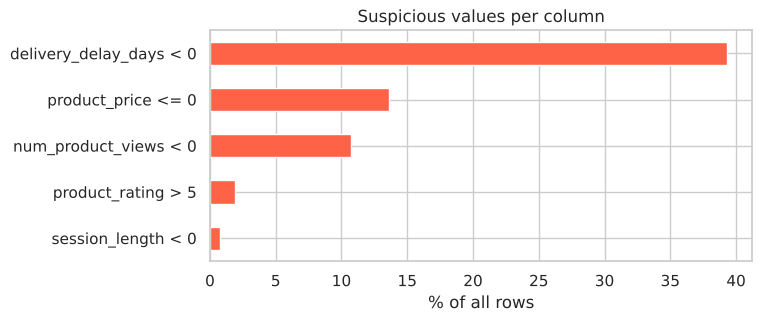

In [5]:
# Impossible / suspicious values
checks = {
    'product_price <= 0'       : (df.product_price <= 0).sum(),
    'num_product_views < 0'    : (df.num_product_views < 0).sum(),
    'session_length < 0'       : (df.session_length_minutes < 0).sum(),
    'product_rating > 5'       : (df.product_rating > 5).sum(),
    'delivery_delay_days < 0'  : (df.delivery_delay_days < 0).sum(),
}
bad = pd.Series(checks).sort_values()
display(bad.to_frame('rows'))

ax = (bad / len(df) * 100).plot(kind='barh', color='tomato', figsize=(7, 3))
ax.set_xlabel('% of all rows'); ax.set_title('Suspicious values per column')
plt.show()

**Interpretation**
- No missing values and no duplicates, so the file is structurally clean.
- But several columns contain **impossible values**: negative prices, negative views, negative session time, and ratings above 5. These look like noise or entry errors.
- `delivery_delay_days < 0` can be valid (delivered *early*), so we keep it.
- Plan: in notebook 02, convert impossible values to NaN and fill them using the median.

## 3. Target Variable

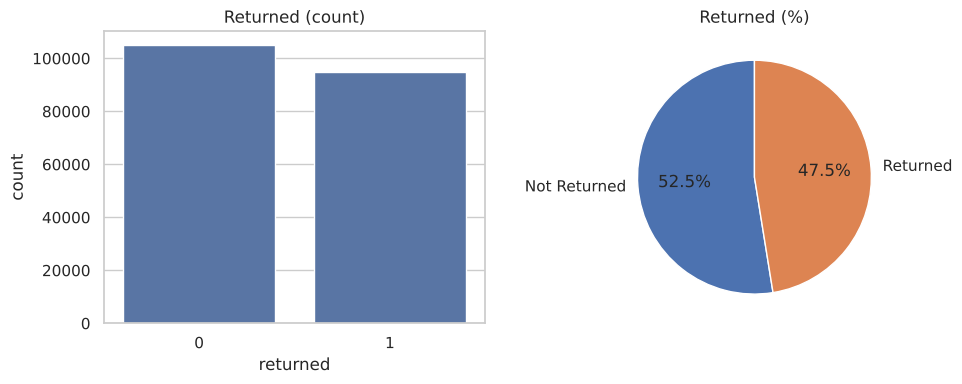

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='returned', data=df, ax=ax[0])
ax[0].set_title('Returned (count)')
df['returned'].value_counts().plot.pie(autopct='%1.1f%%', ax=ax[1],
                                       labels=['Not Returned', 'Returned'], startangle=90)
ax[1].set_ylabel(''); ax[1].set_title('Returned (%)')
plt.tight_layout(); plt.show()

**Interpretation**
- Classes are almost balanced (about 52% vs 48%), so **no SMOTE / resampling is needed**.
- Accuracy is a fair metric here, but we will still also use F1 and ROC-AUC.

## 4. Numeric Features

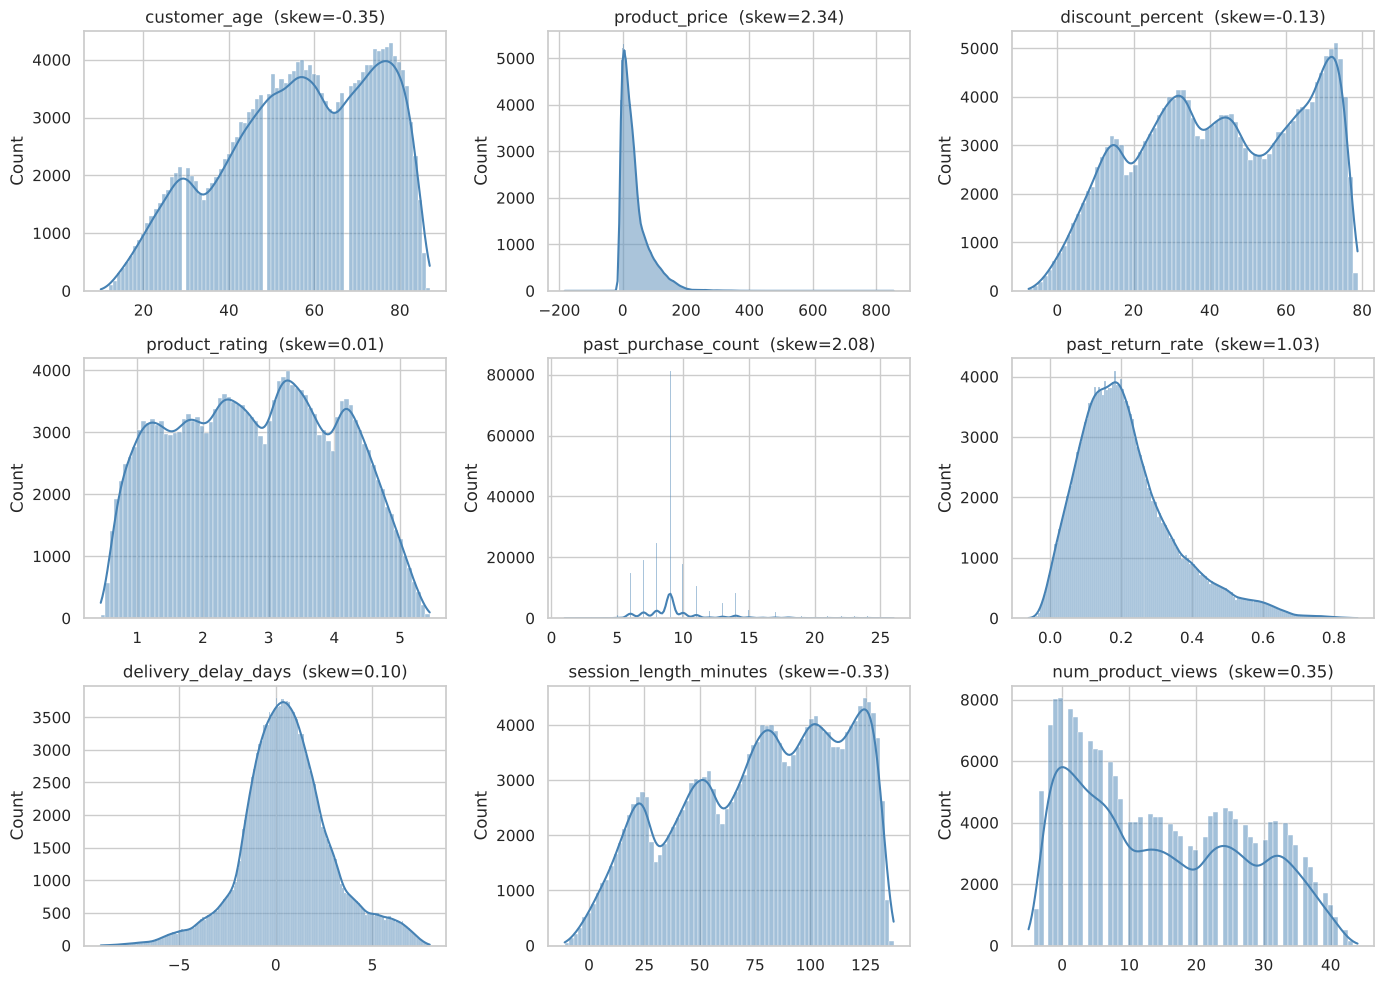

In [7]:
num_cols = ['customer_age', 'product_price', 'discount_percent', 'product_rating',
            'past_purchase_count', 'past_return_rate', 'delivery_delay_days',
            'session_length_minutes', 'num_product_views']
cat_cols = ['device_type', 'product_category', 'shipping_method', 'payment_method']

# Distributions
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'{c}  (skew={df[c].skew():.2f})')
    ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Interpretation**
- `product_price` and `past_purchase_count` are strongly **right-skewed** (a few very large values). A log transform or scaling will help linear models.
- `customer_age`, `session_length_minutes` and `discount_percent` are fairly spread out with no extreme skew.
- Negative values in price / views / session length are visible as the left tails.

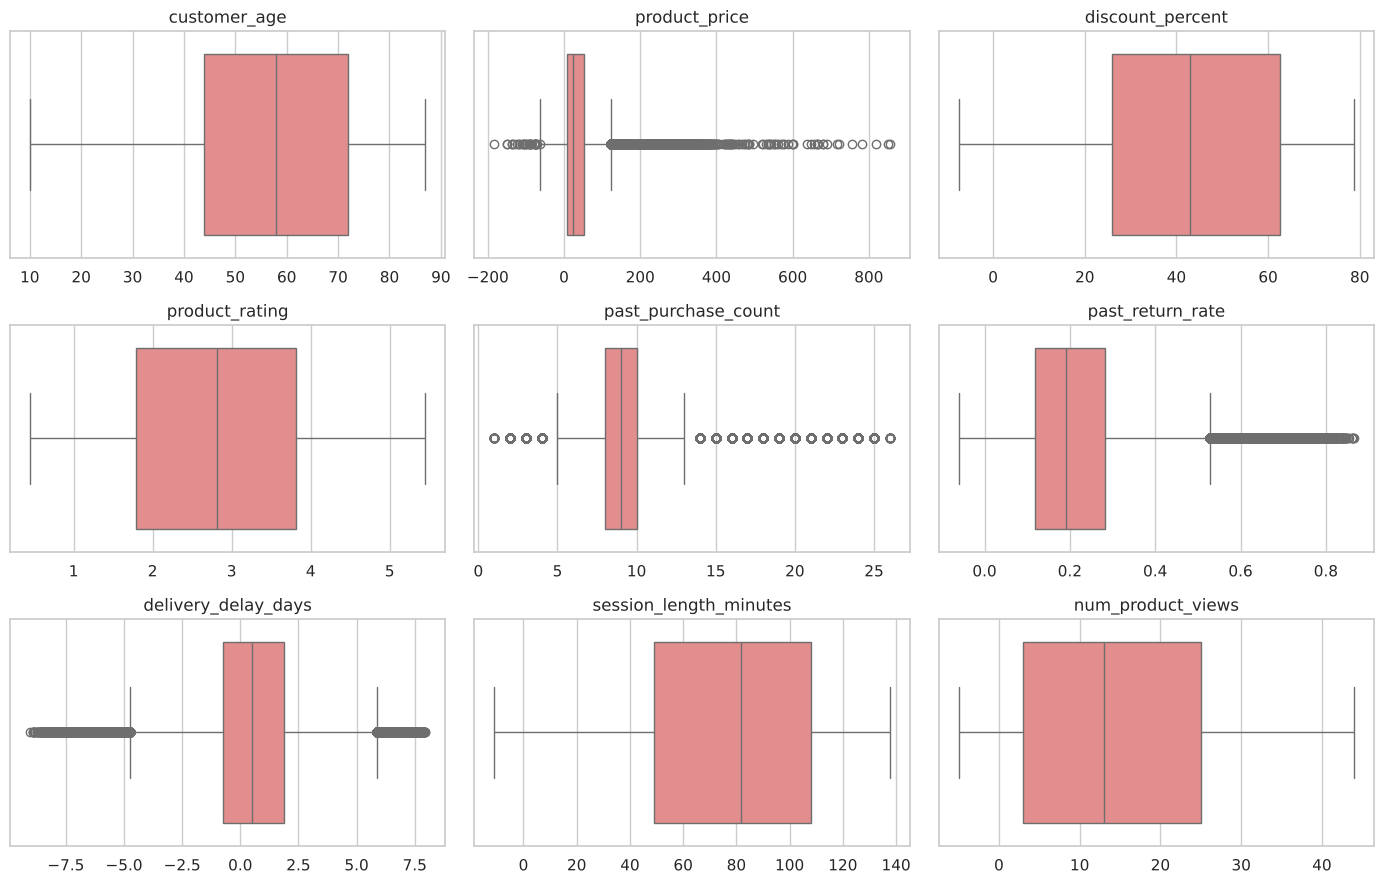

In [8]:
# Outliers with boxplots
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax, color='lightcoral')
    ax.set_title(c); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Interpretation**
- `product_price` has many high outliers (up to ~855), and `past_purchase_count` also has a long tail.
- These high values are plausible (expensive items, loyal customers), so we will **not delete them**. We will reduce their effect with a log transform and scaling instead.

## 5. Categorical Features

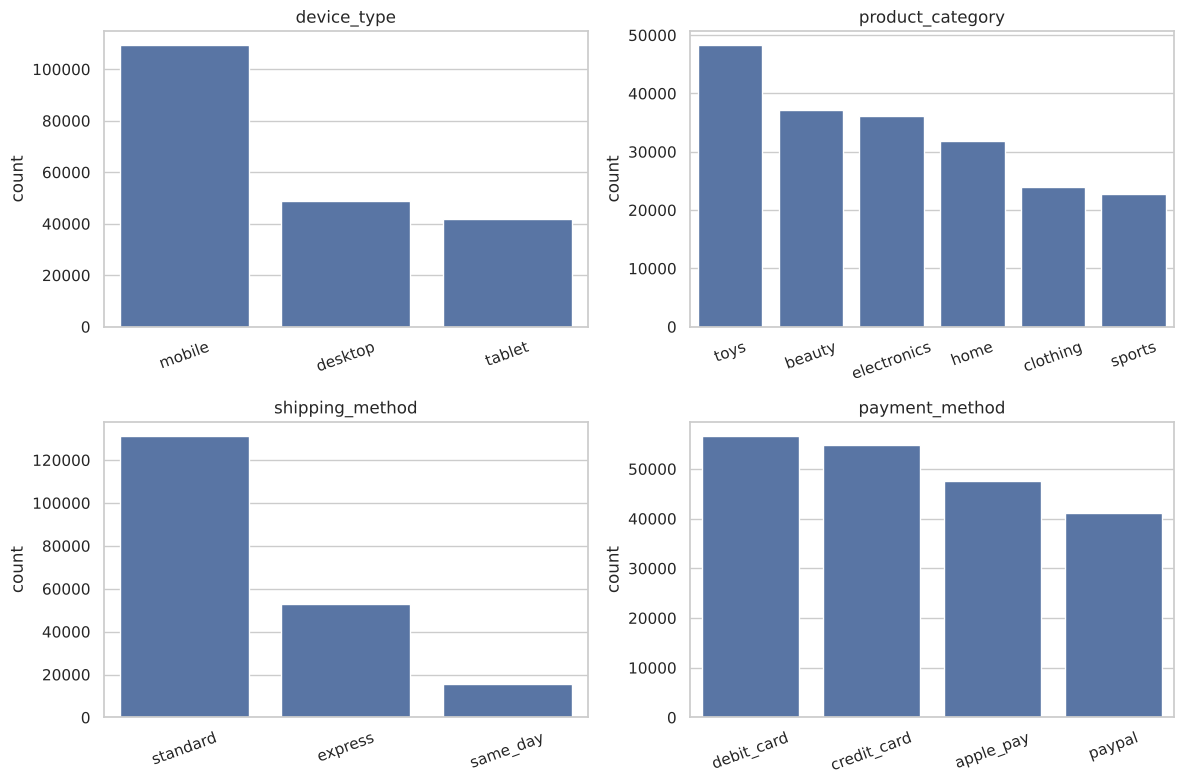

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df[c].value_counts().index
    sns.countplot(x=c, data=df, order=order, ax=ax)
    ax.set_title(c); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Interpretation**
- All categorical columns have few categories (3 to 6), so **one-hot encoding** is safe and will not create too many columns.
- No category is extremely rare.

## 6. Features vs Target

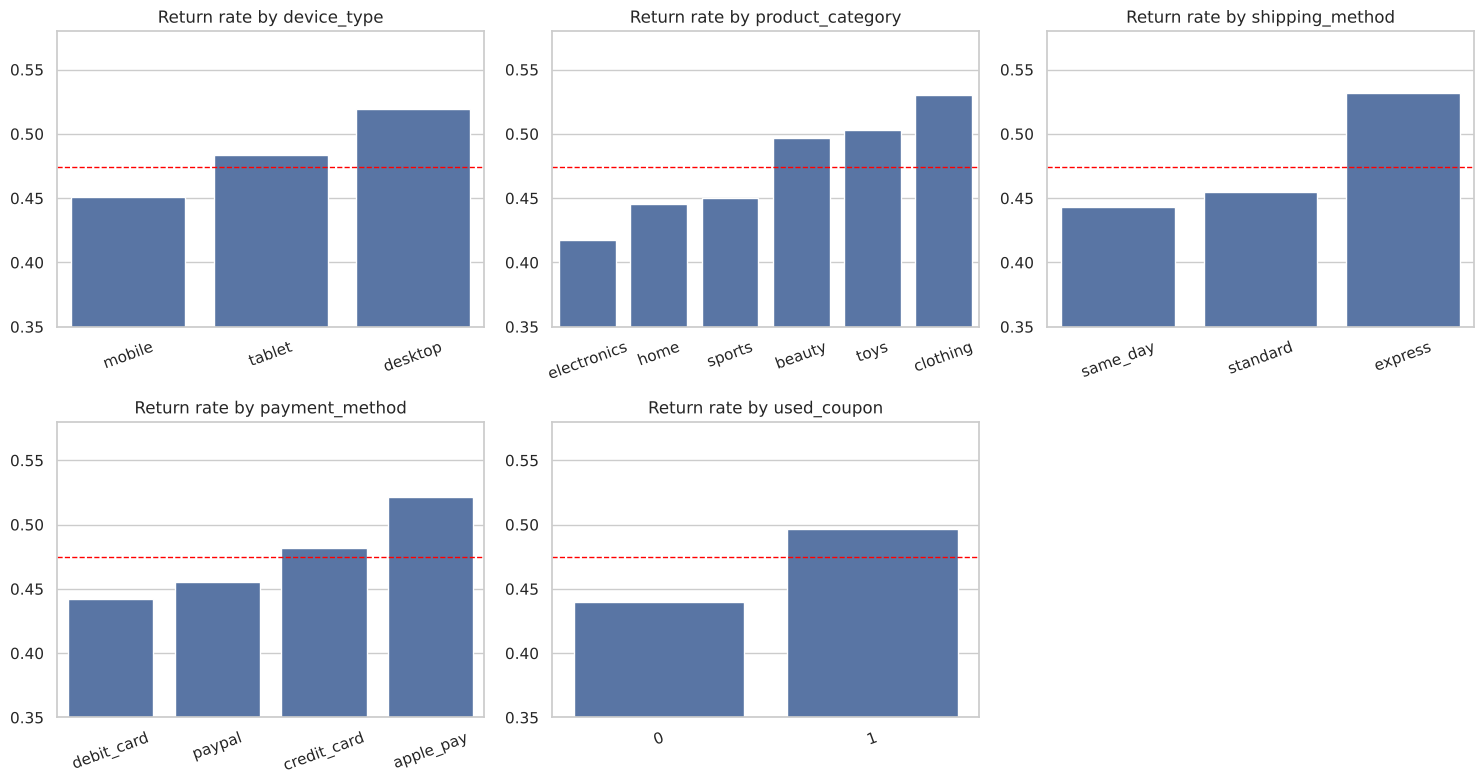

In [10]:
# Return rate for each category (dashed line = overall return rate)
overall = df['returned'].mean()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_cols + ['used_coupon']):
    rate = df.groupby(c)['returned'].mean().sort_values()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(overall, color='red', ls='--', lw=1)
    ax.set_ylim(0.35, 0.58); ax.set_title(f'Return rate by {c}')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
axes[1, 2].axis('off')
plt.tight_layout(); plt.show()

**Interpretation**
- Categories clearly differ in return rate:
  - **Clothing** (~53%) is returned more than **electronics** (~42%).
  - **Express** shipping (~53%) is higher than same-day / standard (~44-46%).
  - **Apple Pay** (~52%) is higher than debit card (~44%), and **desktop** is higher than mobile.
  - Orders that **used a coupon** are returned more (~50% vs ~44%).
- So categorical features carry useful signal.

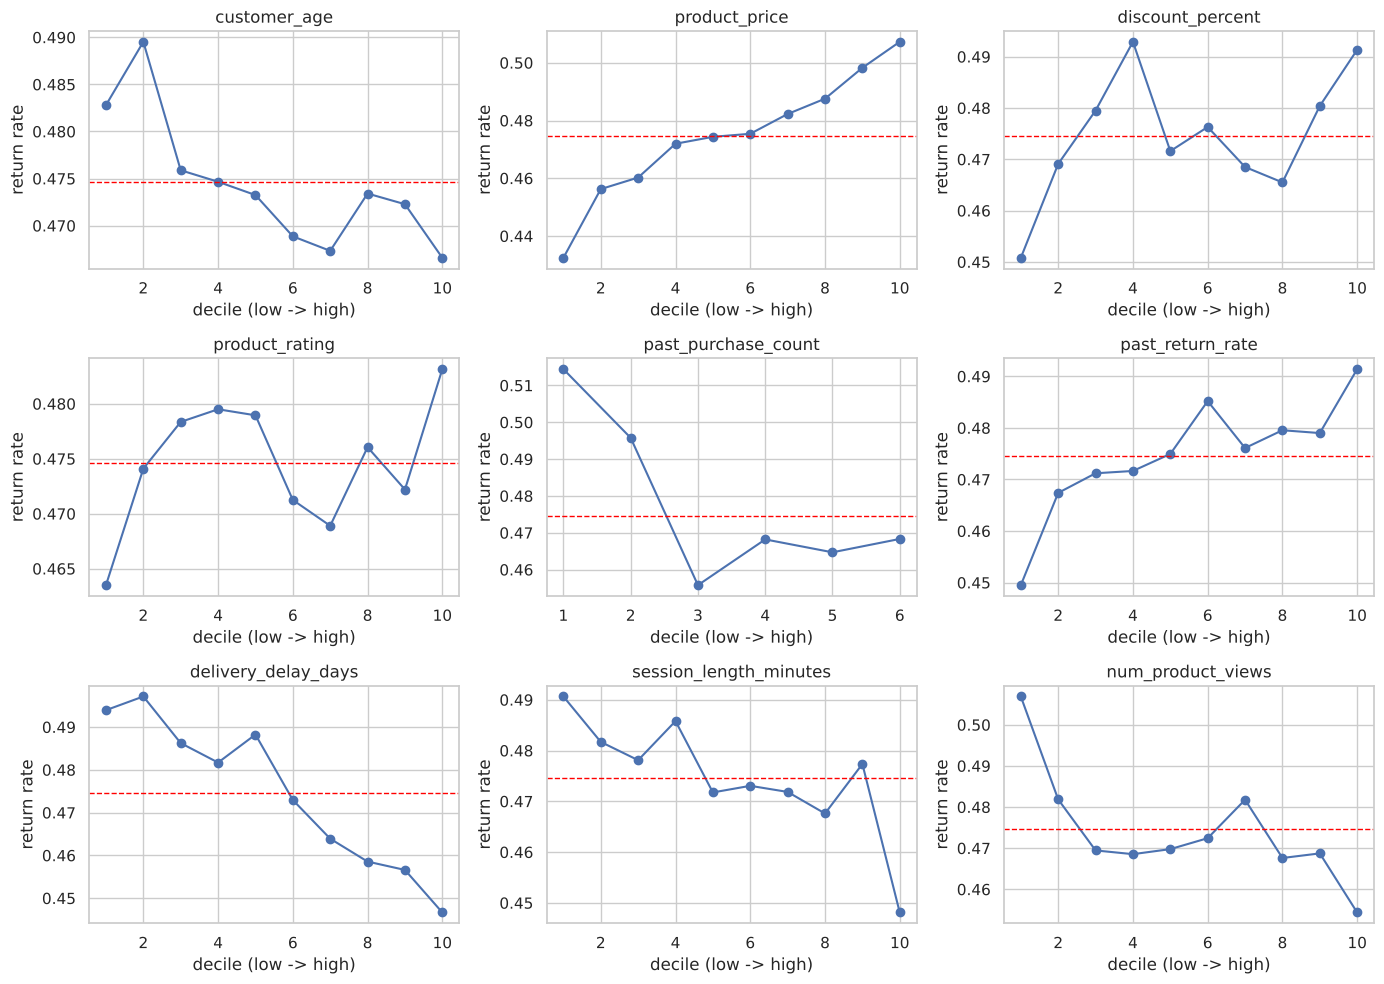

In [11]:
# Return rate across deciles (10 equal-sized groups, low -> high) of each numeric feature
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), num_cols):
    bins = pd.qcut(df[c], 10, duplicates='drop')
    rate = df.groupby(bins, observed=True)['returned'].mean().values
    ax.plot(range(1, len(rate) + 1), rate, marker='o')
    ax.axhline(overall, color='red', ls='--', lw=1)
    ax.set_title(c); ax.set_xlabel('decile (low -> high)'); ax.set_ylabel('return rate')
plt.tight_layout(); plt.show()

**Interpretation**
- Lines that move up or down show a relationship. Flat lines near the red dashed line mean little effect.
- Most numeric features show only a **weak, gentle trend** (e.g. return rate rises with price, from ~43% to ~51% across deciles, and falls with delivery delay, views, session length and purchase count).
- This suggests the signal is spread over many features, so models that combine features (Random Forest, boosting) should do better than a simple linear model.

## 7. Correlation

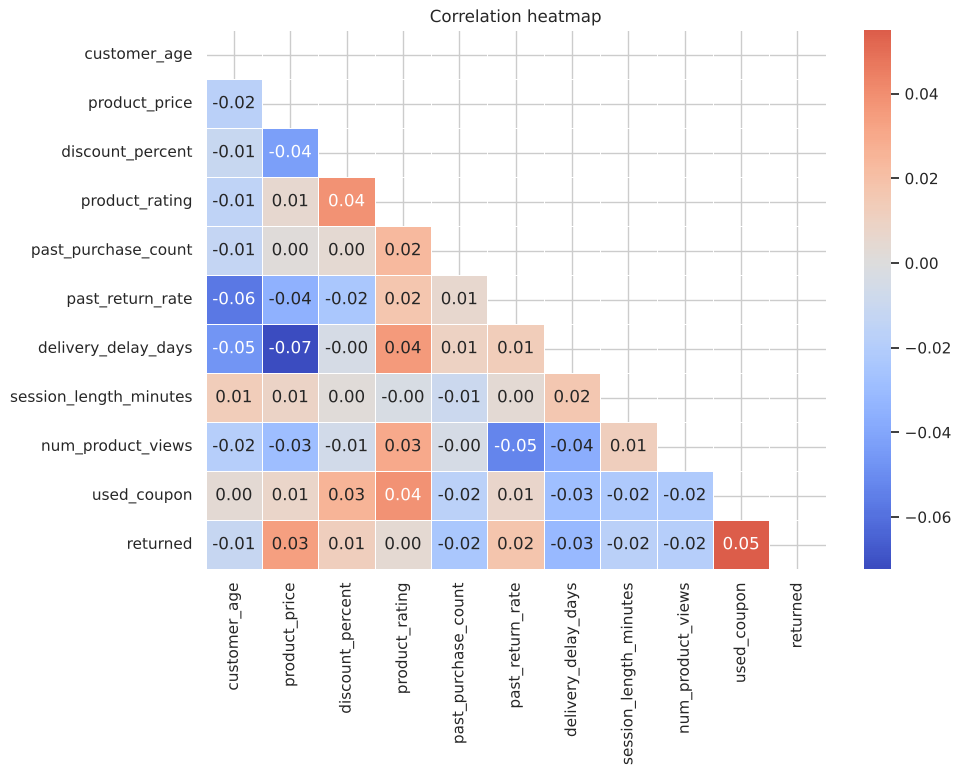

In [12]:
corr = df[num_cols + ['used_coupon', 'returned']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Correlation heatmap'); plt.show()

**Interpretation**
- All correlations with `returned` are **small** (below about 0.06). The strongest are `used_coupon` and `product_price` (positive) and `delivery_delay_days` (negative).
- Features are **not strongly correlated with each other**, so multicollinearity is not a problem.
- Weak linear correlation does not mean useless: patterns may be non-linear or come from feature combinations.

## 8. Feature Interactions

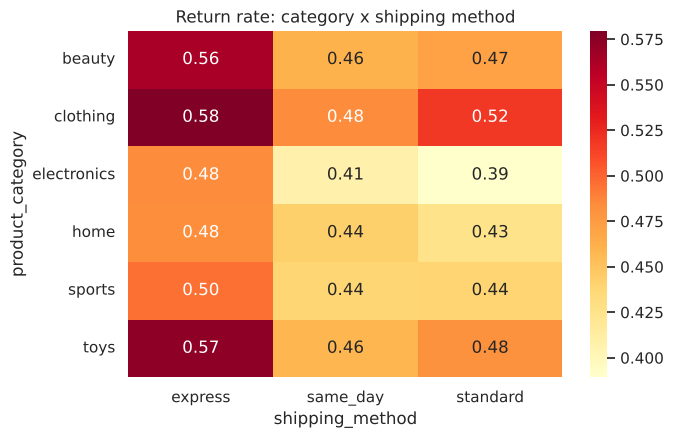

In [13]:
# Return rate for two categorical features together
pivot = df.pivot_table(index='product_category', columns='shipping_method',
                       values='returned', aggfunc='mean')
plt.figure(figsize=(7, 4.5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd')
plt.title('Return rate: category x shipping method'); plt.show()

**Interpretation**
- Combinations matter: the highest return rates appear where a high-return category (clothing, toys, beauty) meets **express** shipping (~56-58%), while electronics with standard shipping is the lowest (~39%).
- This supports trying **feature engineering** and tree-based models later.

## 9. Summary of Findings
| Finding | Action in notebook 02 |
|---|---|
| No missing values, no duplicates | Nothing to remove |
| Impossible values (price ≤ 0, negative views / session time, rating > 5) | Set to NaN, then impute with median |
| `order_id` is only an ID | Drop it |
| Target almost balanced | No resampling |
| `product_price`, `past_purchase_count` right-skewed | Log transform + scaling |
| Categorical features have clear differences | One-hot encoding |
| Weak linear correlations, some interactions | Create engineered features |

➡️ Next: **`02_preprocessing.ipynb`**